# The Policy Makers

Five DQN RL agents use the same training settings with different random seeds. I am comparing their actions and behavior across various checkpoints, then testing whether early behavior can predict later strategies.

## 1. Environment and DQN

In [ ]:
# Install the 2048 game engine if it is not already installed
%pip install Py2048-Engine

In [1]:
# CELL 1 — Imports

from Py2048_Engine.Game import Game
from Py2048_Engine.Exceptions import (
    GameWonException,
    GameLostException
)
import pandas as pd
import random
import json
import time
from pathlib import Path
from collections import deque
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
# CELL 2 — Merge rewards

def merge_score_line(line):
    """
    Calculate the normal 2048 score produced by merging
    one row or column.
    """
    # Remove empty cells
    tiles = [x for x in line if x != 0]
    score = 0
    i = 0
    while i < len(tiles) - 1:
        if tiles[i] == tiles[i + 1]:
            merged_tile = tiles[i] * 2
            score += merged_tile
            # Skip both tiles because they have merged
            i += 2
        else:
            i += 1
    return score

def calculate_merge_reward(state, action):
    """
    Calculate how many 2048 points an action should earn.
    Actions:
    0 = LEFT
    1 = RIGHT
    2 = UP
    3 = DOWN
    """
    # Convert our flat 16-number state back into a 4x4 board
    board = [
        state[0:4],
        state[4:8],
        state[8:12],
        state[12:16]
    ]
    reward = 0
    # LEFT
    if action == 0:
        for row in board:
            reward += merge_score_line(row)
    # RIGHT
    elif action == 1:
        for row in board:
            reward += merge_score_line(row[::-1])
    # UP
    elif action == 2:
        for col in range(4):
            column = [
                board[0][col],
                board[1][col],
                board[2][col],
                board[3][col]
            ]
            reward += merge_score_line(column)
    # DOWN
    elif action == 3:
        for col in range(4):
            column = [
                board[3][col],
                board[2][col],
                board[1][col],
                board[0][col]
            ]
            reward += merge_score_line(column)
    return reward

In [3]:
# CELL 3 — 2048 environment

class Game2048:
    def __init__(self):
        self.actions = ["LEFT", "RIGHT", "UP", "DOWN"]
        self.reset()
    def reset(self):
        """
        Start a brand-new game.
        """
        self.game = Game()
        return self.get_state()
    def get_state(self):
        """
        Convert the 4x4 board into a flat list of 16 numbers.
        Empty cells:
        None -> 0
        """
        board = self.game.getBoard()
        state = []
        for row in board:
            for cell in row:
                if cell is None:
                    state.append(0)
                else:
                    state.append(cell)
        return state
    def step(self, action):
        """
        Perform one action.
        Actions:
        0 = LEFT
        1 = RIGHT
        2 = UP
        3 = DOWN
        Returns:
        next_state, reward, done, valid_move
        """
        state_before = self.get_state()
        # Calculate merge reward BEFORE the move
        reward = calculate_merge_reward(
            state_before,
            action
        )
        done = False
        try:
            if action == 0:
                self.game.left()
            elif action == 1:
                self.game.right()
            elif action == 2:
                self.game.up()
            elif action == 3:
                self.game.down()
        except GameWonException:
            done = True
        except GameLostException:
            done = True
        state_after = self.get_state()
        valid_move = state_before != state_after
        # Penalize moves that do absolutely nothing
        if not valid_move:
            reward = -1
        return (
            state_after,
            reward,
            done,
            valid_move
        )

In [4]:
# CELL 4 — DQN network

class DQN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(16, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 4)
        )
    def forward(self, x):
        return self.network(x)

In [5]:
# CELL 5 — Replay memory

class ReplayMemory:
    def __init__(self, capacity=10000):
        self.memory = deque(maxlen=capacity)
    def push(self, state, action, reward, next_state, done,
             next_legal=None):
        self.memory.append(
            (state, action, reward, next_state, done, next_legal or [])
        )
    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)
    def __len__(self):
        return len(self.memory)

In [6]:
# CELL 6 — State encoding and legal actions

def encode_state(state):
    return np.array(
        [np.log2(x) / 11 if x > 0 else 0 for x in state],
        dtype=np.float32
    )

def slide_line(line):
    tiles = [x for x in line if x != 0]
    result = []
    i = 0
    while i < len(tiles):
        if i + 1 < len(tiles) and tiles[i] == tiles[i + 1]:
            result.append(tiles[i] * 2)
            i += 2
        else:
            result.append(tiles[i])
            i += 1
    return result + [0] * (4 - len(result))

def move_board(state, action):
    board = np.array(state).reshape(4, 4)
    if action == 0:  # LEFT
        moved = np.array([slide_line(row) for row in board])
    elif action == 1:  # RIGHT
        moved = np.array([
            slide_line(row[::-1])[::-1] for row in board
        ])
    elif action == 2:  # UP
        moved = np.array([
            slide_line(board[:, col]) for col in range(4)
        ]).T
    else:  # DOWN
        moved = np.array([
            slide_line(board[::-1, col])[::-1]
            for col in range(4)
        ]).T
    return moved.flatten().tolist()

def legal_actions(state):
    return [
        action for action in range(4)
        if move_board(state, action) != list(state)
    ]

In [7]:
# CELL 7 — Action selection

def choose_action(model, state, epsilon):
    valid_actions = legal_actions(state)
    if not valid_actions:
        return None
    if random.random() < epsilon:
        return random.choice(valid_actions)
    state_tensor = torch.tensor(
        encode_state(state), dtype=torch.float32
    )
    with torch.no_grad():
        q_values = model(state_tensor).clone()
    for action in range(4):
        if action not in valid_actions:
            q_values[action] = -float("inf")
    return int(torch.argmax(q_values).item())

In [8]:
# CELL 8 — DQN update

def train_dqn(
    model, target_model, memory, optimizer,
    batch_size=64, gamma=0.99
):
    if len(memory) < batch_size:
        return None
    batch = memory.sample(batch_size)
    states = torch.tensor(
        np.array([x[0] for x in batch]),
        dtype=torch.float32
    )
    actions = torch.tensor(
        [x[1] for x in batch], dtype=torch.long
    )
    rewards = torch.tensor(
        [x[2] for x in batch], dtype=torch.float32
    )
    next_states = torch.tensor(
        np.array([x[3] for x in batch]),
        dtype=torch.float32
    )
    dones = torch.tensor(
        [x[4] for x in batch], dtype=torch.float32
    )
    next_legal = [x[5] for x in batch]
    current_q = model(states).gather(
        1, actions.unsqueeze(1)
    ).squeeze(1)
    with torch.no_grad():
        next_q_values = target_model(next_states)
        legal_mask = torch.tensor(
            [
                [a in allowed for a in range(4)]
                for allowed in next_legal
            ],
            dtype=torch.bool
        )
        next_q_values = next_q_values.masked_fill(
            ~legal_mask, -float("inf")
        )
        next_q = next_q_values.max(dim=1).values
        next_q = torch.where(
            legal_mask.any(dim=1),
            next_q,
            torch.zeros_like(next_q)
        )
        target_q = rewards + gamma * next_q * (1 - dones)
    loss = nn.SmoothL1Loss()(current_q, target_q)
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=1.0
    )
    optimizer.step()
    return loss.item()

I created a 2048 environment where the agents can move tiles in four directions. The board is converted into numbers that the neural network can use, and invalid moves are excluded when choosing actions. I used a DQN with two hidden layers of 128 neurons each. The agents learn by storing previous moves in replay memory and using those experiences to update the network. I also used a target network to help keep training more stable.

## 2. Agent training

In [9]:
# CELL 9 — Training settings

torch.set_num_threads(1)
output_dir = Path("policy_makers_results")
models_dir = output_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)
agent_seeds = [101, 102, 103, 104, 105]
checkpoints = [100, 200, 400, 800]
training_config = {
    "agent_seeds": agent_seeds,
    "checkpoints": checkpoints,
    "total_episodes": 800,
    "learning_rate": 0.0003,
    "gamma": 0.99,
    "batch_size": 64,
    "memory_capacity": 20000,
    "epsilon_start": 1.0,
    "epsilon_min": 0.05,
    "epsilon_decay": 0.99,
    "target_update_steps": 1000,
    "reward_scale": 100.0,
    "max_steps_per_episode": 5000
}
with open(output_dir / "training_config.json", "w") as f:
    json.dump(training_config, f, indent=4)
print("Agents:", len(agent_seeds))
print("Checkpoints:", checkpoints)
print("Total training episodes:", len(agent_seeds) * 800)
print("Results folder:", output_dir.resolve())

Agents: 5
Checkpoints: [100, 200, 400, 800]
Total training episodes: 4000
Results folder: C:\Users\manis\Documents\USF\Coursework\4thYear1stSemester\CS463\Policy_Makers_2000_Episodes\policy_makers_results


In [10]:
# CELL 10 — Train and save agent checkpoints

def train_policy_maker(agent_id, seed, config):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = Game2048()
    model = DQN()
    target_model = DQN()
    target_model.load_state_dict(model.state_dict())
    target_model.eval()
    optimizer = optim.Adam(
        model.parameters(),
        lr=config["learning_rate"]
    )
    memory = ReplayMemory(
        capacity=config["memory_capacity"]
    )
    epsilon = config["epsilon_start"]
    global_steps = 0
    history = []
    start_time = time.time()
    for episode in range(1, config["total_episodes"] + 1):
        state = env.reset()
        total_reward = 0
        steps = 0
        while steps < config["max_steps_per_episode"]:
            action = choose_action(model, state, epsilon)
            if action is None:
                break
            next_state, reward, done, valid_move = env.step(action)
            next_legal = legal_actions(next_state)
            terminal = done or len(next_legal) == 0
            memory.push(
                encode_state(state),
                action,
                reward / config["reward_scale"],
                encode_state(next_state),
                terminal,
                [] if terminal else next_legal
            )
            train_dqn(
                model,
                target_model,
                memory,
                optimizer,
                batch_size=config["batch_size"],
                gamma=config["gamma"]
            )
            state = next_state
            total_reward += reward
            steps += 1
            global_steps += 1
            if global_steps % config["target_update_steps"] == 0:
                target_model.load_state_dict(model.state_dict())
            if terminal:
                break
        history.append({
            "agent_id": agent_id,
            "seed": seed,
            "episode": episode,
            "reward": total_reward,
            "highest_tile": max(state),
            "steps": steps,
            "epsilon": epsilon
        })
        epsilon = max(
            config["epsilon_min"],
            epsilon * config["epsilon_decay"]
        )
        if episode in config["checkpoints"]:
            model_path = models_dir / (
                f"agent_{agent_id}_episode_{episode}.pt"
            )
            torch.save(model.state_dict(), model_path)
            pd.DataFrame(history).to_csv(
                output_dir / f"agent_{agent_id}_training.csv",
                index=False
            )
            recent = history[-25:]
            avg_reward = np.mean(
                [row["reward"] for row in recent]
            )
            avg_tile = np.mean(
                [row["highest_tile"] for row in recent]
            )
            elapsed = (time.time() - start_time) / 60
            print(
                f"Agent {agent_id} | "
                f"Episode {episode} | "
                f"Avg Reward: {avg_reward:.1f} | "
                f"Avg Tile: {avg_tile:.1f} | "
                f"Time: {elapsed:.1f} min",
                flush=True
            )
    return pd.DataFrame(history)

In [11]:
# CELL 11 — Train or load the five agents

all_histories = []
for agent_id, seed in enumerate(agent_seeds, start=1):
    print(f"\nStarting Agent {agent_id} (seed={seed})")
    history_file = output_dir / f"agent_{agent_id}_training.csv"
    saved_models = [
        models_dir / f"agent_{agent_id}_episode_{cp}.pt"
        for cp in checkpoints
    ]
    if history_file.exists() and all(
        path.exists() for path in saved_models
    ):
        print("Saved results found. Skipping training.")
        history = pd.read_csv(history_file)
    else:
        history = train_policy_maker(
            agent_id,
            seed,
            training_config
        )
    all_histories.append(history)
training_results = pd.concat(
    all_histories,
    ignore_index=True
)
training_results.to_csv(
    output_dir / "all_training_results.csv",
    index=False
)
print("\nAll five agents complete!")
print("Total records:", len(training_results))


Starting Agent 1 (seed=101)
Saved results found. Skipping training.

Starting Agent 2 (seed=102)
Saved results found. Skipping training.

Starting Agent 3 (seed=103)
Saved results found. Skipping training.

Starting Agent 4 (seed=104)
Saved results found. Skipping training.

Starting Agent 5 (seed=105)
Saved results found. Skipping training.

All five agents complete!
Total records: 4000


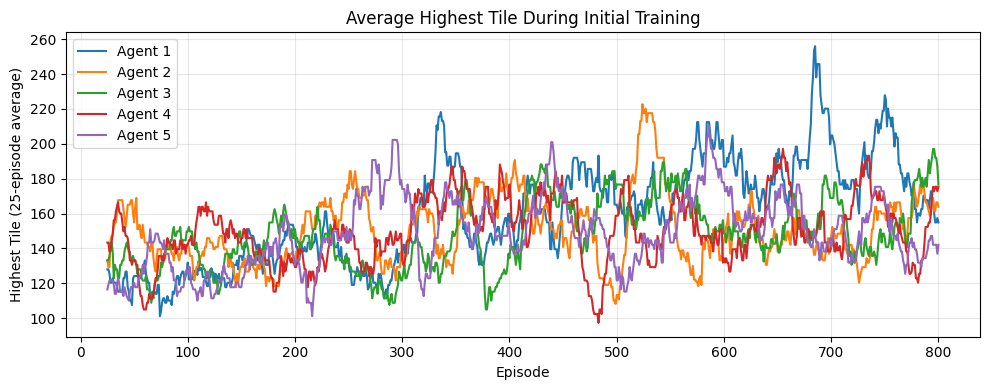

Average performance over final 50 training episodes:
           reward  highest_tile   steps
agent_id                               
1         1982.00        162.56  191.84
2         1917.84        160.64  187.30
3         1980.96        171.52  192.78
4         1844.80        151.04  182.16
5         1751.84        144.00  179.44


In [12]:
# CELL 12 — Training performance

window = 25
fig, ax = plt.subplots(figsize=(10, 4))
for agent_id in range(1, 6):
    agent_data = training_results[
        training_results["agent_id"] == agent_id
    ].sort_values("episode")
    tile_avg = agent_data["highest_tile"].rolling(window).mean()
    ax.plot(
        agent_data["episode"],
        tile_avg,
        label=f"Agent {agent_id}"
    )
ax.set_title("Average Highest Tile During Initial Training")
ax.set_xlabel("Episode")
ax.set_ylabel("Highest Tile (25-episode average)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
final_summary = (
    training_results[
        training_results["episode"] > 750
    ]
    .groupby("agent_id")[["reward", "highest_tile", "steps"]]
    .mean()
    .round(2)
)
print("Average performance over final 50 training episodes:")
print(final_summary)

I trained five agents using the same settings but different random seeds to see whether they would learn different ways of playing 2048. Each agent was initially trained for 800 episodes, with models saved at several checkpoints (expanded to 2000 episodes later). The agents started by making more random moves and gradually relied more on their learned decisions. Their training performance was not identical even though the settings were the same. This gave me five separately trained agents to compare which helps to answer my first main question - that independently trained RL models could develop different policy behaviors and decision making even while being trained in the same way. 

## 3. Evaluation and behavior data

In [13]:
# CELL 13 — Load saved checkpoints

agent_ids = list(range(1, len(agent_seeds) + 1))
saved_policies = {}
for agent_id in agent_ids:
    for checkpoint in checkpoints:
        model_path = models_dir / (
            f"agent_{agent_id}_episode_{checkpoint}.pt"
        )
        if not model_path.exists():
            raise FileNotFoundError(model_path)
        policy = DQN()
        policy.load_state_dict(
            torch.load(model_path, map_location="cpu",
                       weights_only=True)
        )
        policy.eval()
        saved_policies[(agent_id, checkpoint)] = policy
print("Loaded policies:", len(saved_policies))

Loaded policies: 20


In [14]:
# CELL 14 — Shared evaluation boards

shared_boards_path = output_dir / "shared_boards.csv"
if shared_boards_path.exists():
    shared_boards_df = pd.read_csv(shared_boards_path)
    shared_boards = shared_boards_df[[f"cell_{i}" for i in range(16)]].values.tolist()
    print("Loaded shared_boards.csv:", len(shared_boards_df), "records")
else:
    random.seed(2026)
    np.random.seed(2026)
    target_boards = 600
    shared_boards = []
    seen_boards = set()
    game_number = 0
    while len(shared_boards) < target_boards:
        game_number += 1
        game_env = Game2048()
        state = game_env.reset()
        steps = 0
        while steps < 500:
            allowed = legal_actions(state)
            if not allowed:
                break
            action = random.choice(allowed)
            next_state, reward, done, valid_move = game_env.step(action)
            state = next_state
            steps += 1
            if steps >= 10 and steps % 5 == 0:
                board_key = tuple(state)
                if board_key not in seen_boards:
                    seen_boards.add(board_key)
                    shared_boards.append(state.copy())
            if done or len(shared_boards) >= target_boards:
                break
    shared_boards_df = pd.DataFrame(
        shared_boards,
        columns=[f"cell_{i}" for i in range(16)]
    )
    shared_boards_df.insert(
        0, "board_id", range(len(shared_boards_df))
    )
    shared_boards_df.to_csv(
        shared_boards_path,
        index=False
    )
    print("Generated boards:", len(shared_boards_df))
    print("Games used:", game_number)
    print(shared_boards_df.head())

Loaded shared_boards.csv: 600 records


In [15]:
# CELL 15 — Actions on shared boards

board_states = shared_boards_df[[f"cell_{i}" for i in range(16)]].to_numpy(dtype=int)
if (output_dir / "shared_decisions.csv").exists():
    shared_decisions_df = pd.read_csv(output_dir / "shared_decisions.csv")
    print("Loaded shared_decisions.csv:", len(shared_decisions_df), "records")
else:
    shared_decisions = []
    for (agent_id, checkpoint), policy in saved_policies.items():
        for board_id, state in enumerate(board_states):
            action = choose_action(
                policy, state.tolist(), epsilon=0.0
            )
            shared_decisions.append({
                "agent_id": agent_id,
                "checkpoint": checkpoint,
                "board_id": board_id,
                "action": action
            })
    shared_decisions_df = pd.DataFrame(shared_decisions)
    shared_decisions_df.to_csv(
        output_dir / "shared_decisions.csv",
        index=False
    )
    print("Recorded decisions:", len(shared_decisions_df))
    print(shared_decisions_df.head())

Loaded shared_decisions.csv: 12000 records


In [16]:
# CELL 16 — Full-game behavior

def evaluate_policy_games(policy, agent_id, checkpoint, count, seed_base):
    action_names = ["left", "right", "up", "down"]
    corner_names = ["top_left", "top_right", "bottom_left", "bottom_right"]
    corner_positions = [0, 3, 12, 15]
    rows = []
    for game_number in range(count):
        random.seed(seed_base + game_number)
        env = Game2048()
        state = env.reset()
        action_counts = np.zeros(4, dtype=int)
        corner_counts = np.zeros(4, dtype=float)
        merge_moves = corner_moves = empty_total = total_reward = steps = 0
        while steps < 5000:
            action = choose_action(policy, state, epsilon=0.0)
            if action is None:
                break
            next_state, reward, done, _ = env.step(action)
            action_counts[action] += 1
            if reward > 0:
                merge_moves += 1
            highest = max(next_state)
            occupied_corners = [i for i, pos in enumerate(corner_positions)
                                if next_state[pos] == highest]
            if occupied_corners:
                corner_moves += 1
                for idx in occupied_corners:
                    corner_counts[idx] += 1 / len(occupied_corners)
            empty_total += next_state.count(0)
            total_reward += reward
            steps += 1
            state = next_state
            if done:
                break
        if steps == 0:
            raise RuntimeError(f"Zero-step game for agent {agent_id} checkpoint {checkpoint}")
        record = {
            "agent_id": agent_id, "checkpoint": checkpoint,
            "game_number": game_number, "reward": total_reward,
            "highest_tile": max(state), "steps": steps,
            "merge_rate": merge_moves / steps,
            "corner_rate": corner_moves / steps,
            "avg_empty_cells": empty_total / steps
        }
        for i, name in enumerate(action_names):
            record[f"action_{name}"] = action_counts[i] / steps
        for i, name in enumerate(corner_names):
            record[f"corner_{name}"] = corner_counts[i] / steps
        rows.append(record)
    return rows

if (output_dir / "game_behavior.csv").exists():
    game_behavior_df = pd.read_csv(output_dir / "game_behavior.csv")
    game_records = game_behavior_df.to_dict("records")
    print("Loaded game_behavior.csv:", len(game_behavior_df), "records")
else:
    evaluation_games = 30
    game_records = []
    for (agent_id, checkpoint), policy in saved_policies.items():
        game_records.extend(evaluate_policy_games(
            policy, agent_id, checkpoint, evaluation_games, 50000
        ))
        print(f"Agent {agent_id}, Episode {checkpoint}: "
              f"{evaluation_games} games complete", flush=True)
    game_behavior_df = pd.DataFrame(game_records)
    game_behavior_df.to_csv(
        output_dir / "game_behavior.csv",
        index=False
    )
    print("\nTotal games evaluated:", len(game_behavior_df))
    print(game_behavior_df.head())

Loaded game_behavior.csv: 600 records


In [17]:
# CELL 17 — Strategy fingerprints

strategy_features = [
    "merge_rate",
    "corner_rate",
    "avg_empty_cells",
    "action_left",
    "action_right",
    "action_up",
    "action_down",
    "corner_top_left",
    "corner_top_right",
    "corner_bottom_left",
    "corner_bottom_right"
]
performance_features = [
    "reward",
    "highest_tile",
    "steps"
]
fingerprints_df = (
    game_behavior_df
    .groupby(["agent_id", "checkpoint"])[
        strategy_features + performance_features
    ]
    .mean()
    .reset_index()
)
fingerprints_df.to_csv(
    output_dir / "strategy_fingerprints.csv",
    index=False
)
print("Strategy fingerprints:", len(fingerprints_df))
print()
print(fingerprints_df.round(3).to_string(index=False))

Strategy fingerprints: 20

 agent_id  checkpoint  merge_rate  corner_rate  avg_empty_cells  action_left  action_right  action_up  action_down  corner_top_left  corner_top_right  corner_bottom_left  corner_bottom_right   reward  highest_tile   steps
        1         100       0.680        0.263            4.183        0.503         0.064      0.254        0.179            0.210             0.001               0.051                0.001 2058.133       173.867 196.900
        1         200       0.664        0.113            4.155        0.172         0.317      0.253        0.258            0.011             0.053               0.008                0.041 1431.067       124.800 152.633
        1         400       0.695        0.324            4.163        0.054         0.537      0.226        0.183            0.001             0.207               0.002                0.115 2571.067       204.800 232.667
        1         800       0.697        0.210            3.936        0.231         

I evaluated the saved agents using shared board positions and complete games. The shared boards let me compare what different agents would do in the exact same situation. I also collected information about their behavior, including how often they merged tiles, preferred corners, kept empty spaces, and chose certain directions. These measurements were used to create strategy fingerprints, which give a numerical description of how each agent plays instead of only looking at its score.

## 4. Data checks and episode-800 agreement

The first agreement test uses the episode-800 policies. I later repeat the test at episode 2,000 on the same shared boards. 
Agreement means two agents select the same action (not necessarily that the action is good or bad).

Total boards: 600
Duplicate boards: 0

Game stages:
stage
Middle    294
Late      214
Early      92
Name: count, dtype: int64

Legal moves:
legal_moves
0      6
2     65
3    215
4    314
Name: count, dtype: int64

Average empty cells: 3.74


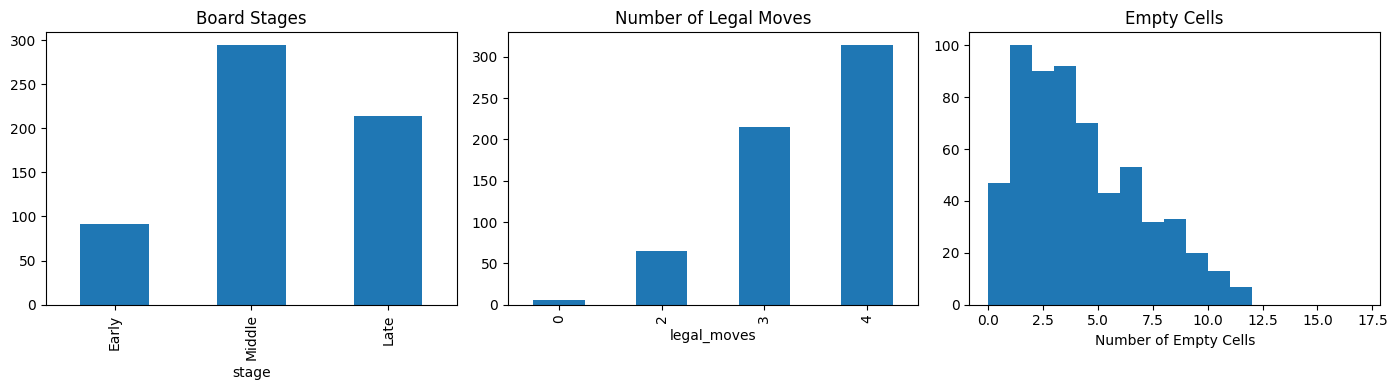

In [18]:
# CELL 18 — Shared-board data checks

board_records = []
for state in board_states:
    state = state.tolist()
    highest = max(state)
    empty = state.count(0)
    allowed = legal_actions(state)
    if highest <= 16:
        stage = "Early"
    elif highest <= 64:
        stage = "Middle"
    else:
        stage = "Late"
    board_records.append({
        "highest_tile": highest,
        "empty_cells": empty,
        "legal_moves": len(allowed),
        "stage": stage
    })
board_stats_df = pd.DataFrame(board_records)
print("Total boards:", len(board_stats_df))
print("Duplicate boards:",
      len(board_stats_df) - len(set(map(tuple, board_states))))
print()
print("Game stages:")
print(board_stats_df["stage"].value_counts())
print()
print("Legal moves:")
print(board_stats_df["legal_moves"].value_counts().sort_index())
print()
print("Average empty cells:",
      round(board_stats_df["empty_cells"].mean(), 2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
board_stats_df["stage"].value_counts().reindex(
    ["Early", "Middle", "Late"], fill_value=0
).plot.bar(ax=axes[0], title="Board Stages")
board_stats_df["legal_moves"].value_counts().sort_index().plot.bar(
    ax=axes[1], title="Number of Legal Moves"
)
axes[2].hist(board_stats_df["empty_cells"], bins=range(18))
axes[2].set_title("Empty Cells")
axes[2].set_xlabel("Number of Empty Cells")
plt.tight_layout()
plt.show()
board_stats_df.to_csv(
    output_dir / "shared_board_statistics.csv", index=False
)

I checked the shared boards to make sure the comparisons were based on valid game situations. I also looked at how many legal moves were available because some boards give agents fewer choices. At episode 800, the average agreement between agents was about 41.3%, dropping to 35.6% when all four moves were legal. This shows that the agents were already making different decisions in the same situations. Just to be clear, agreement only measures whether they choose the same move, not whether one agent plays better (because anyways I am not checking for that).

## 5. Training continuation and policy comparison

In [19]:
# CELL 19 — Continuation settings

extension_dir = output_dir / "extension_2000"
extension_models_dir = extension_dir / "models"
extension_models_dir.mkdir(parents=True, exist_ok=True)
extension_checkpoints = [1000, 1200, 1600, 2000]
all_checkpoints_2000 = [100, 200, 400, 800] + extension_checkpoints
extension_config = {
    **training_config,
    "starting_episode": 800,
    "total_episodes": 2000,
    "new_checkpoints": extension_checkpoints,
    "resume_note": "Model weights only: optimizer, replay memory and target-update counter reset at episode 800."
}
with open(extension_dir / "extension_config.json", "w") as f:
    json.dump(extension_config, f, indent=4)
for agent_id in agent_ids:
    original = models_dir / f"agent_{agent_id}_episode_800.pt"
    if not original.exists():
        raise FileNotFoundError(f"Required original checkpoint missing: {original}")
    history_file = output_dir / f"agent_{agent_id}_training.csv"
    if not history_file.exists():
        raise FileNotFoundError(f"Required original history missing: {history_file}")
print("Original 800-episode weights and histories found for all five agents.")
print("New results directory:", extension_dir.resolve())

Original 800-episode weights and histories found for all five agents.
New results directory: C:\Users\manis\Documents\USF\Coursework\4thYear1stSemester\CS463\Policy_Makers_2000_Episodes\policy_makers_results\extension_2000


In [20]:
# CELL 20 — Continue training to 2,000 episodes

def continue_policy_maker(agent_id, seed, config):
    # The original 800-episode model is loaded; the optimizer and replay
    # memory cannot be restored because they were not saved previously.
    original_history = pd.read_csv(output_dir / f"agent_{agent_id}_training.csv")
    if len(original_history) != 800 or int(original_history["episode"].iloc[-1]) != 800:
        raise ValueError(f"Agent {agent_id}: expected 800 original history rows")
    random.seed(seed + 800000)
    np.random.seed(seed + 800000)
    torch.manual_seed(seed + 800000)
    model = DQN()
    model.load_state_dict(torch.load(
        models_dir / f"agent_{agent_id}_episode_800.pt",
        map_location="cpu", weights_only=True
    ))
    target_model = DQN()
    target_model.load_state_dict(model.state_dict())
    target_model.eval()
    optimizer = optim.Adam(model.parameters(), lr=config["learning_rate"])
    memory = ReplayMemory(capacity=config["memory_capacity"])
    env = Game2048()
    epsilon = max(config["epsilon_min"],
                  float(original_history["epsilon"].iloc[-1]) * config["epsilon_decay"])
    global_steps = 0
    new_rows = []
    start_time = time.time()
    for episode in range(801, 2001):
        state = env.reset()
        total_reward = 0
        steps = 0
        while steps < config["max_steps_per_episode"]:
            action = choose_action(model, state, epsilon)
            if action is None:
                break
            next_state, reward, done, _ = env.step(action)
            next_legal = legal_actions(next_state)
            terminal = done or len(next_legal) == 0
            memory.push(encode_state(state), action,
                        reward / config["reward_scale"],
                        encode_state(next_state), terminal,
                        [] if terminal else next_legal)
            train_dqn(model, target_model, memory, optimizer,
                         batch_size=config["batch_size"], gamma=config["gamma"])
            state = next_state
            total_reward += reward
            steps += 1
            global_steps += 1
            if global_steps % config["target_update_steps"] == 0:
                target_model.load_state_dict(model.state_dict())
            if terminal:
                break
        new_rows.append({
            "agent_id": agent_id, "seed": seed, "episode": episode,
            "reward": total_reward, "highest_tile": max(state),
            "steps": steps, "epsilon": epsilon
        })
        epsilon = max(config["epsilon_min"], epsilon * config["epsilon_decay"])
        if episode in extension_checkpoints:
            checkpoint_file = extension_models_dir / f"agent_{agent_id}_episode_{episode}.pt"
            torch.save(model.state_dict(), checkpoint_file)
            # Save history at every checkpoint so partial runs remain usable.
            combined = pd.concat([original_history, pd.DataFrame(new_rows)],
                                 ignore_index=True)
            combined.to_csv(extension_dir / f"agent_{agent_id}_training_2000.csv",
                            index=False)
            recent = new_rows[-25:]
            print(f"Agent {agent_id} | Episode {episode} | "
                  f"Avg reward {np.mean([r['reward'] for r in recent]):.1f} | "
                  f"Avg highest tile {np.mean([r['highest_tile'] for r in recent]):.1f} | "
                  f"Elapsed {(time.time()-start_time)/60:.1f} min", flush=True)
    return pd.concat([original_history, pd.DataFrame(new_rows)], ignore_index=True)
extension_histories = []
for agent_id, seed in enumerate(agent_seeds, start=1):
    expected_models = [extension_models_dir / f"agent_{agent_id}_episode_{cp}.pt"
                       for cp in extension_checkpoints]
    history_path = extension_dir / f"agent_{agent_id}_training_2000.csv"
    if history_path.exists() and all(p.exists() for p in expected_models):
        history = pd.read_csv(history_path)
        if len(history) != 2000 or int(history["episode"].iloc[-1]) != 2000:
            raise ValueError(f"Agent {agent_id}: incomplete saved extension history")
        print(f"Agent {agent_id}: 2,000-episode extension already saved; skipping.")
    else:
        print(f"Continuing agent {agent_id} from episode 800...", flush=True)
        history = continue_policy_maker(agent_id, seed, training_config)
    extension_histories.append(history)
training_results_2000 = pd.concat(extension_histories, ignore_index=True)
training_results_2000.to_csv(extension_dir / "all_training_results_2000.csv", index=False)
print("Extended training records:", len(training_results_2000))

Agent 1: 2,000-episode extension already saved; skipping.
Agent 2: 2,000-episode extension already saved; skipping.
Agent 3: 2,000-episode extension already saved; skipping.
Agent 4: 2,000-episode extension already saved; skipping.
Agent 5: 2,000-episode extension already saved; skipping.
Extended training records: 10000


In [21]:
# CELL 21 — Load extended checkpoints

extended_policies = dict(saved_policies)
for agent_id in agent_ids:
    for checkpoint in extension_checkpoints:
        path = extension_models_dir / f"agent_{agent_id}_episode_{checkpoint}.pt"
        if not path.exists():
            raise FileNotFoundError(path)
        model = DQN()
        model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
        model.eval()
        extended_policies[(agent_id, checkpoint)] = model
print("Total available policies:", len(extended_policies))

Total available policies: 40


The comparison below uses the same boards at episodes 800 and 2,000. A decrease in agreement means the agents make less similar action choices; it does not show whether their scores improved.

Policy agreement at episodes 800 and 2000 (same shared boards):
            valid_boards  four_legal_moves
checkpoint                                
800                0.413             0.356
2000               0.335             0.269

Agreement by game stage:
                   count   mean
checkpoint stage               
800        Early      92  0.398
           Late      211  0.394
           Middle    291  0.431
2000       Early      92  0.271
           Late      211  0.364
           Middle    291  0.333

Agreement by number of legal moves:
                        count   mean
checkpoint legal_moves              
800        2               65  0.594
           3              215  0.440
           4              314  0.356
2000       2               65  0.502
           3              215  0.379
           4              314  0.269

Change from episode 800 to 2000: -0.078 (percentage-point change = -7.8)
Interpretation: The agents chose the same actions less often at episode 200

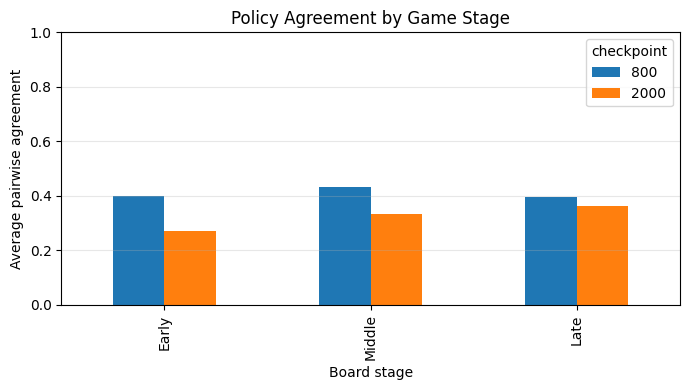

In [22]:
# CELL 22 — Policy agreement at episodes 800 and 2,000

# Compare episode-800 and episode-2000 policies on the same shared boards.
# Exclude boards with no legal actions.
valid_ids = board_stats_df.index[board_stats_df["legal_moves"] > 0]
four_move_ids = board_stats_df.index[board_stats_df["legal_moves"] == 4]
agreement_rows = []
board_agreement_rows = []
for checkpoint in [800, 2000]:
    if checkpoint == 800:
        actions = shared_decisions_df[
            shared_decisions_df["checkpoint"] == 800
        ].pivot(index="board_id", columns="agent_id", values="action")
    else:
        decisions = []
        for agent_id in agent_ids:
            policy = extended_policies[(agent_id, 2000)]
            for board_id, state in enumerate(board_states):
                decisions.append({
                    "board_id": board_id,
                    "agent_id": agent_id,
                    "action": choose_action(policy, state.tolist(), epsilon=0.0)
                })
        actions = pd.DataFrame(decisions).pivot(
            index="board_id", columns="agent_id", values="action"
        )
    for agent_a, agent_b in combinations(agent_ids, 2):
        agreement_rows.append({
            "checkpoint": checkpoint,
            "agent_a": agent_a,
            "agent_b": agent_b,
            "valid_boards": (actions.loc[valid_ids, agent_a] ==
                             actions.loc[valid_ids, agent_b]).mean(),
            "four_legal_moves": (actions.loc[four_move_ids, agent_a] ==
                                 actions.loc[four_move_ids, agent_b]).mean()
        })
    for board_id in valid_ids:
        choices = actions.loc[board_id]
        pair_matches = [
            choices[a] == choices[b]
            for a, b in combinations(agent_ids, 2)
        ]
        board_agreement_rows.append({
            "checkpoint": checkpoint,
            "board_id": board_id,
            "stage": board_stats_df.loc[board_id, "stage"],
            "legal_moves": board_stats_df.loc[board_id, "legal_moves"],
            "agreement": np.mean(pair_matches)
        })
agreement_comparison_df = pd.DataFrame(agreement_rows)
board_agreement_comparison_df = pd.DataFrame(board_agreement_rows)
print("Policy agreement at episodes 800 and 2000 (same shared boards):")
print(agreement_comparison_df.groupby("checkpoint")[[
    "valid_boards", "four_legal_moves"
]].mean().round(3).to_string())
print("\nAgreement by game stage:")
print(board_agreement_comparison_df.groupby(["checkpoint", "stage"])[
    "agreement"
].agg(["count", "mean"]).round(3).to_string())
print("\nAgreement by number of legal moves:")
print(board_agreement_comparison_df.groupby(["checkpoint", "legal_moves"])[
    "agreement"
].agg(["count", "mean"]).round(3).to_string())
old_agreement = agreement_comparison_df[
    agreement_comparison_df["checkpoint"] == 800
]["valid_boards"].mean()
new_agreement = agreement_comparison_df[
    agreement_comparison_df["checkpoint"] == 2000
]["valid_boards"].mean()
change = new_agreement - old_agreement
print(f"\nChange from episode 800 to 2000: {change:+.3f} "
      "(percentage-point change = " f"{change * 100:+.1f})")
if change > 0:
    print("Interpretation: The agents chose the same actions more often at episode 2000.")
elif change < 0:
    print("Interpretation: The agents chose the same actions less often at episode 2000.")
else:
    print("Interpretation: Average action agreement was unchanged.")
print("This measures action similarity, not game-playing quality or statistical significance.")
agreement_comparison_df.to_csv(
    extension_dir / "policy_agreement_800_vs_2000_pairs.csv", index=False
)
board_agreement_comparison_df.to_csv(
    extension_dir / "policy_agreement_800_vs_2000_boards.csv", index=False
)
# Show agreement by stage for both checkpoints.
stage_plot = (board_agreement_comparison_df.groupby(["checkpoint", "stage"])["agreement"]
              .mean().unstack(0).reindex(["Early", "Middle", "Late"]))
stage_plot.plot.bar(figsize=(7, 4))
plt.ylabel("Average pairwise agreement")
plt.xlabel("Board stage")
plt.title("Policy Agreement by Game Stage")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# CELL 23 — Evaluate extended checkpoints

new_behavior_path = extension_dir / "game_behavior_new_checkpoints.csv"
expected_pairs = {(a, cp) for a in agent_ids for cp in extension_checkpoints}
if new_behavior_path.exists():
    new_behavior_df = pd.read_csv(new_behavior_path)
    observed_pairs = set(zip(new_behavior_df.agent_id, new_behavior_df.checkpoint))
    if observed_pairs != expected_pairs or len(new_behavior_df) != 600:
        raise ValueError("Existing extension evaluation is incomplete; do not silently reuse")
    print("Loaded new checkpoint evaluations:", len(new_behavior_df))
else:
    new_rows = []
    for agent_id in agent_ids:
        for cp in extension_checkpoints:
            new_rows.extend(evaluate_policy_games(
                extended_policies[(agent_id, cp)], agent_id, cp, 30, 50000))
            print(f"Evaluated agent {agent_id} at episode {cp}", flush=True)
    new_behavior_df = pd.DataFrame(new_rows)
    new_behavior_df.to_csv(new_behavior_path, index=False)
all_behavior_2000 = pd.concat([game_behavior_df, new_behavior_df], ignore_index=True)
all_behavior_2000.to_csv(extension_dir / "game_behavior_all_checkpoints.csv", index=False)
print("All checkpoint evaluation games:", len(all_behavior_2000))

Loaded new checkpoint evaluations: 600
All checkpoint evaluation games: 1200


Best training outcomes by agent:
          training_best_tile  training_best_reward
agent_id                                          
1                        512                  8040
2                        512                  7100
3                        512                  8268
4                        512                  7872
5                        512                  6796

Final checkpoint evaluation (30 games per agent):
 agent_id  checkpoint  mean_reward  median_reward  best_tile  mean_tile  mean_steps  reached_1024  reached_2048
        1        2000       2149.6         1994.0        512    177.067     204.500         0.000           0.0
        2        2000       3160.8         2822.0        512    252.800     267.800         0.000           0.0
        3        2000       2128.0         1834.0        512    179.200     200.333         0.000           0.0
        4        2000       3577.2         2830.0       1024    273.067     293.067         0.033           0.0

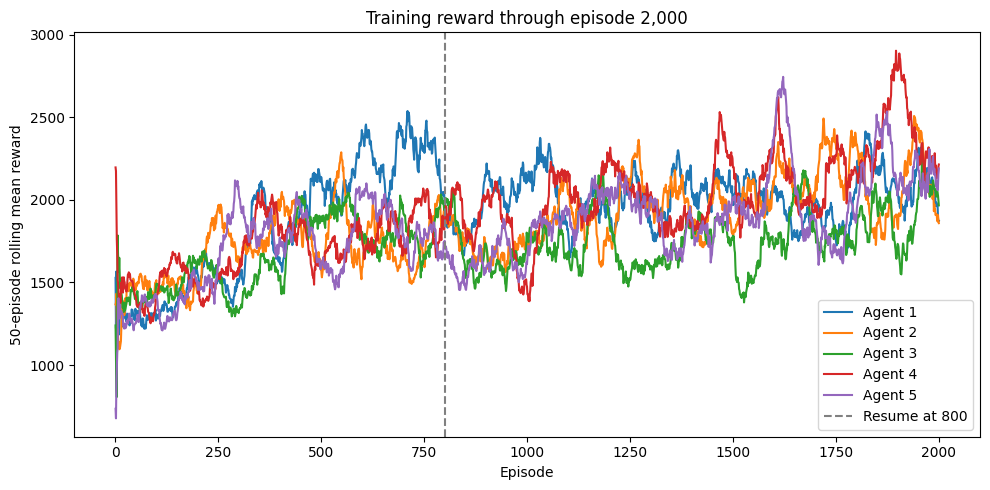

In [24]:
# CELL 24 — Training and evaluation summary

training_summary_2000 = (
    training_results_2000.groupby("agent_id")
    .agg(training_best_tile=("highest_tile", "max"),
         training_best_reward=("reward", "max"))
)
evaluation_summary_2000 = (
    all_behavior_2000.groupby(["agent_id", "checkpoint"])
    .agg(mean_reward=("reward", "mean"), median_reward=("reward", "median"),
         best_tile=("highest_tile", "max"), mean_tile=("highest_tile", "mean"),
         mean_steps=("steps", "mean"),
         reached_1024=("highest_tile", lambda x: (x >= 1024).mean()),
         reached_2048=("highest_tile", lambda x: (x >= 2048).mean()))
    .reset_index()
)
evaluation_summary_2000.to_csv(extension_dir / "checkpoint_performance_summary.csv", index=False)
print("Best training outcomes by agent:")
print(training_summary_2000.to_string())
print("\nFinal checkpoint evaluation (30 games per agent):")
print(evaluation_summary_2000[evaluation_summary_2000.checkpoint == 2000].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 5))
for agent_id, group in training_results_2000.groupby("agent_id"):
    rolling = group.sort_values("episode")["reward"].rolling(50, min_periods=1).mean()
    ax.plot(group.sort_values("episode")["episode"], rolling, label=f"Agent {agent_id}")
ax.axvline(800, linestyle="--", color="gray", label="Resume at 800")
ax.set(title="Training reward through episode 2,000", xlabel="Episode", ylabel="50-episode rolling mean reward")
ax.legend()
plt.tight_layout()
plt.show()

I continued training the same five agents from episode 800 to episode 2,000 and compared their behavior again. Their average agreement decreased from 41.3% to 33.5%, while agreement on boards with four legal moves dropped from 35.6% to 26.9%. This suggests that the agents became more different in their decisions as training continued. However, their performance did not consistently improve. The continuation also restarted replay memory and the optimizer, so the extra training should not be treated as a completely uninterrupted run.

## 6. Strategy development and stability

In [25]:
# CELL 25 — Extended strategy fingerprints

fingerprints_2000 = (
    all_behavior_2000.groupby(["agent_id", "checkpoint"])[
        strategy_features + performance_features
    ].mean().reset_index()
)
fingerprints_2000.to_csv(extension_dir / "strategy_fingerprints_2000.csv", index=False)
print("Extended strategy fingerprints:", len(fingerprints_2000))
print(fingerprints_2000[fingerprints_2000.checkpoint == 2000].round(3).to_string(index=False))

Extended strategy fingerprints: 40
 agent_id  checkpoint  merge_rate  corner_rate  avg_empty_cells  action_left  action_right  action_up  action_down  corner_top_left  corner_top_right  corner_bottom_left  corner_bottom_right  reward  highest_tile   steps
        1        2000       0.681        0.268            3.925        0.160         0.318      0.168        0.354            0.014             0.043               0.019                0.192  2149.6       177.067 204.500
        2        2000       0.698        0.533            4.297        0.485         0.046      0.390        0.080            0.528             0.004               0.001                0.000  3160.8       252.800 267.800
        3        2000       0.678        0.292            3.937        0.205         0.262      0.416        0.117            0.044             0.212               0.021                0.016  2128.0       179.200 200.333
        4        2000       0.691        0.251            3.615        0.276     

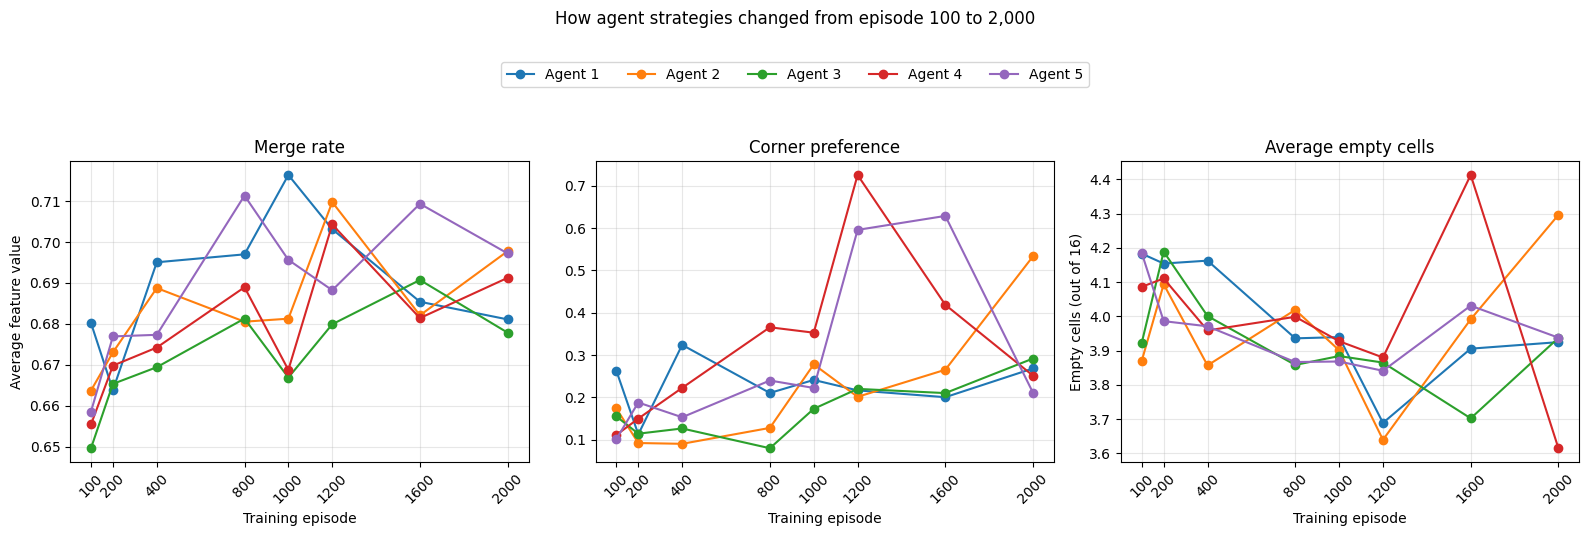

In [26]:
# CELL 26 — Strategy development across checkpoints

# Compare the same behavioral features for all five agents.
plot_features = [
    ("merge_rate", "Merge rate"),
    ("corner_rate", "Corner preference"),
    ("avg_empty_cells", "Average empty cells")
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (feature, title) in zip(axes, plot_features):
    for agent_id in agent_ids:
        agent_data = fingerprints_2000[
            fingerprints_2000["agent_id"] == agent_id
        ].sort_values("checkpoint")
        ax.plot(
            agent_data["checkpoint"], agent_data[feature],
            marker="o", label=f"Agent {agent_id}"
        )
    ax.set_title(title)
    ax.set_xlabel("Training episode")
    ax.set_xticks(all_checkpoints_2000)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Average feature value")
axes[2].set_ylabel("Empty cells (out of 16)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.08))
fig.suptitle("How agent strategies changed from episode 100 to 2,000", y=1.18)
plt.tight_layout()
plt.show()

In [27]:
# CELL 27 — Strategy stability and evaluation variability

stability_features = [
    "merge_rate", "corner_rate", "avg_empty_cells",
    "action_left", "action_right", "action_up", "action_down"
]
# Bootstrap estimates evaluation variability; this is not a significance test.
stability_2000 = fingerprints_2000.copy()
stability_2000["avg_empty_cells"] /= 16.0
rng_2000 = np.random.default_rng(2026)
bootstrap_2000 = []
for (agent_id, checkpoint), group in all_behavior_2000.groupby(["agent_id", "checkpoint"]):
    values = group[stability_features].to_numpy(dtype=float).copy()
    values[:, 2] /= 16
    center = values.mean(axis=0)
    for repeat in range(500):
        sample = values[rng_2000.integers(0, len(values), len(values))]
        bootstrap_2000.append({"agent_id": agent_id, "checkpoint": checkpoint,
                               "noise_distance": np.linalg.norm(sample.mean(axis=0) - center)})
bootstrap_2000_df = pd.DataFrame(bootstrap_2000)
noise_2000 = bootstrap_2000_df.groupby(["agent_id", "checkpoint"])[
    "noise_distance"].quantile(.95)
change_rows_2000 = []
for agent_id in agent_ids:
    agent_data = stability_2000[stability_2000.agent_id == agent_id].set_index("checkpoint")
    for earlier, later in zip(all_checkpoints_2000[:-1], all_checkpoints_2000[1:]):
        before = agent_data.loc[earlier, stability_features].to_numpy(dtype=float)
        after = agent_data.loc[later, stability_features].to_numpy(dtype=float)
        distance = np.linalg.norm(after - before)
        noise = np.hypot(noise_2000.loc[(agent_id, earlier)],
                         noise_2000.loc[(agent_id, later)])
        change_rows_2000.append({
            "agent_id": agent_id, "earlier": earlier, "later": later,
            "distance": distance, "change_per_100_episodes": distance * 100 / (later-earlier),
            "estimated_noise": noise, "change_exceeds_noise": distance > noise
        })
changes_2000_df = pd.DataFrame(change_rows_2000)
changes_2000_df.to_csv(extension_dir / "strategy_stability_2000.csv", index=False)
print("Average strategy changes across five agents:")
print(changes_2000_df.groupby(["earlier", "later"])[["distance", "estimated_noise"]].mean().round(4).to_string())
print("\nLate-stage changes (800 onward):")
print(changes_2000_df[changes_2000_df.earlier >= 800].groupby(
    ["earlier", "later"])[["distance", "change_per_100_episodes"]].mean().round(4))
print("Note: exceeding bootstrap noise is a heuristic, not a formal significance test.")

Average strategy changes across five agents:
               distance  estimated_noise
earlier later                           
100     200      0.2717           0.0942
200     400      0.2681           0.1023
400     800      0.4304           0.1175
800     1000     0.4469           0.1193
1000    1200     0.4622           0.1315
1200    1600     0.5517           0.1339
1600    2000     0.5059           0.1346

Late-stage changes (800 onward):
               distance  change_per_100_episodes
earlier later                                   
800     1000     0.4469                   0.2235
1000    1200     0.4622                   0.2311
1200    1600     0.5517                   0.1379
1600    2000     0.5059                   0.1265
Note: exceeding bootstrap noise is a heuristic, not a formal significance test.


In [28]:
# CELL 28 — Final 2,000-episode evaluation

final_eval_path = extension_dir / "final_2000_evaluation_100_games.csv"
if final_eval_path.exists():
    final_eval_2000 = pd.read_csv(final_eval_path)
    if len(final_eval_2000) != 500 or set(final_eval_2000.agent_id) != set(agent_ids):
        raise ValueError("Existing final evaluation file is incomplete")
    print("Loaded final 500 evaluation games.")
else:
    final_rows = []
    for agent_id in agent_ids:
        final_rows.extend(evaluate_policy_games(
            extended_policies[(agent_id, 2000)], agent_id, 2000, 100, 80000))
        print(f"Agent {agent_id}: 100 final evaluation games completed", flush=True)
    final_eval_2000 = pd.DataFrame(final_rows)
    final_eval_2000.to_csv(final_eval_path, index=False)
final_eval_summary_2000 = final_eval_2000.groupby("agent_id").agg(
    games=("highest_tile", "size"),
    average_reward=("reward", "mean"),
    best_tile=("highest_tile", "max"),
    average_tile=("highest_tile", "mean"),
    reached_1024=("highest_tile", lambda x: (x >= 1024).sum()),
    reached_2048=("highest_tile", lambda x: (x >= 2048).sum()),
    average_steps=("steps", "mean")
)
final_eval_summary_2000.to_csv(extension_dir / "final_2000_summary.csv")
print("Final episode-2000 results (100 games per agent):")
print(final_eval_summary_2000.round(2).to_string())
print("\nOverall 1024 success rate:",
      round((final_eval_2000.highest_tile >= 1024).mean(), 4))
print("Overall 2048 success rate:",
      round((final_eval_2000.highest_tile >= 2048).mean(), 4))

Loaded final 500 evaluation games.
Final episode-2000 results (100 games per agent):
          games  average_reward  best_tile  average_tile  reached_1024  reached_2048  average_steps
agent_id                                                                                           
1           100         2529.20        512        196.80             0             0         231.67
2           100         3313.12        512        263.36             0             0         277.67
3           100         1789.88        512        148.80             0             0         178.05
4           100         3392.04       1024        258.24             1             0         285.51
5           100         2565.20        512        204.16             0             0         232.17

Overall 1024 success rate: 0.002
Overall 2048 success rate: 0.0


I compared the strategy fingerprints across checkpoints to see how each agent's behavior changed during training. The features included merge rate, corner preference, average empty spaces, and action frequencies. Some behaviors changed over time, but the agents did not all develop in the same direction. I also evaluated the final agents over 100 games each. Their average rewards ranged from about 1,790 to 3,392. These rewards represent the total points earned from merging tiles during a game such as 2 + 2 = 4 reward, 16 + 16 = 32 reward etc. No agent could reach the 2048 tile but could get to 512 comfortably and on rare occasions, 1024. This shows that the agents developed different behaviors but they were still limited in how well they could play.

## 7. Predicting later strategies

In [29]:
# CELL 29 — Prediction setup

prediction_features = [
    "merge_rate", "corner_rate", "avg_empty_cells",
    "action_right", "action_down"
]
# Use the saved fingerprints; no additional games or training are needed.
prediction_pairs = [
    (100, 800), (200, 800), (400, 800),
    (400, 1200), (800, 1200),
    (800, 1600), (1000, 1600),
    (1200, 2000), (1600, 2000)
]
horizon_fingerprints = fingerprints_2000.copy()
required_columns = {"agent_id", "checkpoint", *prediction_features}
if not required_columns.issubset(horizon_fingerprints.columns):
    raise ValueError("Saved fingerprints are missing required columns")
if horizon_fingerprints.duplicated(["agent_id", "checkpoint"]).any():
    raise ValueError("Duplicate agent/checkpoint fingerprints found")
horizon_data = horizon_fingerprints[
    ["agent_id", "checkpoint"] + prediction_features
].copy()
horizon_data["avg_empty_cells"] /= 16.0
for source, target in prediction_pairs:
    for checkpoint in (source, target):
        present = set(horizon_data.loc[
            horizon_data.checkpoint == checkpoint, "agent_id"
        ])
        if present != set(agent_ids):
            raise ValueError(f"Incomplete agent fingerprints at episode {checkpoint}")
print("Prediction pairs:", len(prediction_pairs))
print("Independent agents:", len(agent_ids))
print("Fingerprints available:", len(horizon_fingerprints))

Prediction pairs: 9
Independent agents: 5
Fingerprints available: 40


In [30]:
# CELL 30 — Compare six prediction methods

all_prediction_rows = []
all_feature_rows = []
for source, target in prediction_pairs:
    source_df = horizon_data[horizon_data.checkpoint == source].set_index(
        "agent_id")[prediction_features]
    target_df = horizon_data[horizon_data.checkpoint == target].set_index(
        "agent_id")[prediction_features]
    for held_out_agent in agent_ids:
        train_ids = [agent for agent in agent_ids if agent != held_out_agent]
        X_train = source_df.loc[train_ids].to_numpy(dtype=float)
        y_train = target_df.loc[train_ids].to_numpy(dtype=float)
        X_test = source_df.loc[[held_out_agent]].to_numpy(dtype=float)
        y_test = target_df.loc[[held_out_agent]].to_numpy(dtype=float)
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
        ridge = Ridge(alpha=10.0)
        ridge.fit(X_train_scaled, y_train)
        predictions = {
            "Ridge": np.clip(ridge.predict(X_test_scaled), 0, 1),
            "Persistence": X_test.copy(),
            "Training mean": y_train.mean(axis=0, keepdims=True)
        }
        for k in (1, 2):
            knn = KNeighborsRegressor(n_neighbors=k, weights="uniform")
            knn.fit(X_train_scaled, y_train)
            predictions[f"KNN (k={k})"] = np.clip(
                knn.predict(X_test_scaled), 0, 1)
        change_model = Ridge(alpha=10.0)
        change_model.fit(X_train_scaled, y_train - X_train)
        predicted_change = change_model.predict(X_test_scaled)
        predictions["Ridge (change)"] = np.clip(X_test + predicted_change, 0, 1)
        for method, predicted in predictions.items():
            all_prediction_rows.append({
                "source": source, "target": target, "gap": target - source,
                "held_out_agent": held_out_agent, "method": method,
                "mae": mean_absolute_error(y_test.ravel(), predicted.ravel())
            })
            for i, feature in enumerate(prediction_features):
                all_feature_rows.append({
                    "source": source, "target": target, "gap": target - source,
                    "held_out_agent": held_out_agent, "method": method,
                    "feature": feature, "actual": y_test[0, i],
                    "predicted": predicted[0, i],
                    "absolute_error": abs(y_test[0, i] - predicted[0, i])
                })
all_method_results = pd.DataFrame(all_prediction_rows)
all_method_features = pd.DataFrame(all_feature_rows)
all_method_results.to_csv(
    extension_dir / "prediction_all_six_methods.csv", index=False)
all_method_features.to_csv(
    extension_dir / "prediction_all_six_methods_features.csv", index=False)
method_summary = all_method_results.groupby(
    ["source", "target", "gap", "method"])["mae"].mean().unstack()

In [31]:
# CELL 31 — Prediction results

method_names = ["Ridge", "Ridge (change)", "KNN (k=1)",
                "KNN (k=2)", "Persistence", "Training mean"]
method_summary = method_summary[method_names]
mean_errors = method_summary.mean().sort_values()
win_counts = method_summary.idxmin(axis=1).value_counts().reindex(
    method_names, fill_value=0)
method_comparison = pd.DataFrame({
    "average_pair_mae": mean_errors.reindex(method_names),
    "pairs_with_lowest_mae": win_counts
}).sort_values("average_pair_mae")
method_comparison.to_csv(extension_dir / "prediction_method_comparison.csv")
pair_winners = method_summary.copy()
pair_winners["best_method"] = method_summary.idxmin(axis=1)
pair_winners.to_csv(extension_dir / "prediction_all_method_pairs.csv")
print("Overall comparison (each checkpoint pair weighted equally):")
print(method_comparison.round(4).to_string())
print("\nPrediction MAE by checkpoint pair (lower is better):")
print(method_summary.round(4).to_string())

Overall comparison (each checkpoint pair weighted equally):
                average_pair_mae  pairs_with_lowest_mae
Training mean             0.0919                      5
Ridge                     0.0981                      3
KNN (k=2)                 0.1029                      0
Persistence               0.1126                      1
Ridge (change)            0.1169                      0
KNN (k=1)                 0.1277                      0

Prediction MAE by checkpoint pair (lower is better):
method              Ridge  Ridge (change)  KNN (k=1)  KNN (k=2)  Persistence  Training mean
source target gap                                                                          
100    800    700  0.0655          0.0865     0.1099     0.0769       0.0912         0.0785
200    800    600  0.0803          0.0923     0.1227     0.0997       0.1035         0.0785
400    800    400  0.0782          0.0881     0.0975     0.0812       0.1084         0.0785
       1200   800  0.1687         

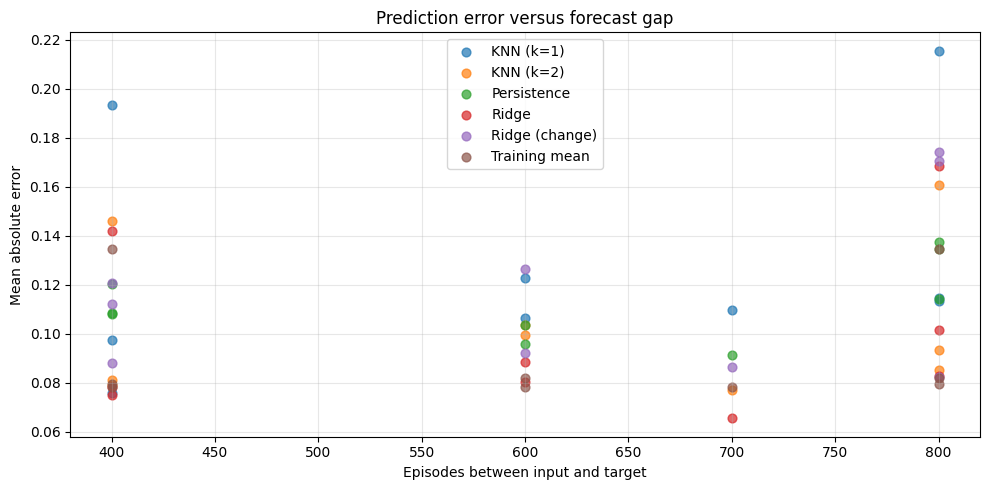

Mean error grouped by gap and method:
method  KNN (k=1)  KNN (k=2)  Persistence   Ridge  Ridge (change)  Training mean
gap                                                                             
400        0.1222     0.1022       0.1122  0.0984          0.1069         0.0975
600        0.1145     0.1016       0.0997  0.0844          0.1093         0.0802
700        0.1099     0.0769       0.0912  0.0655          0.0865         0.0785
800        0.1478     0.1132       0.1289  0.1177          0.1422         0.0987


In [32]:
# CELL 32 — Prediction error versus forecast gap

fig, ax = plt.subplots(figsize=(10, 5))
for method, group in all_method_results.groupby("method"):
    by_pair = group.groupby(["source", "target", "gap"], as_index=False)["mae"].mean()
    ax.scatter(by_pair["gap"], by_pair["mae"], label=method, s=40, alpha=0.7)
ax.set(xlabel="Episodes between input and target", ylabel="Mean absolute error",
       title="Prediction error versus forecast gap")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
print("Mean error grouped by gap and method:")
print(all_method_results.groupby(["gap", "method"])["mae"].mean()
      .unstack().round(4).to_string())

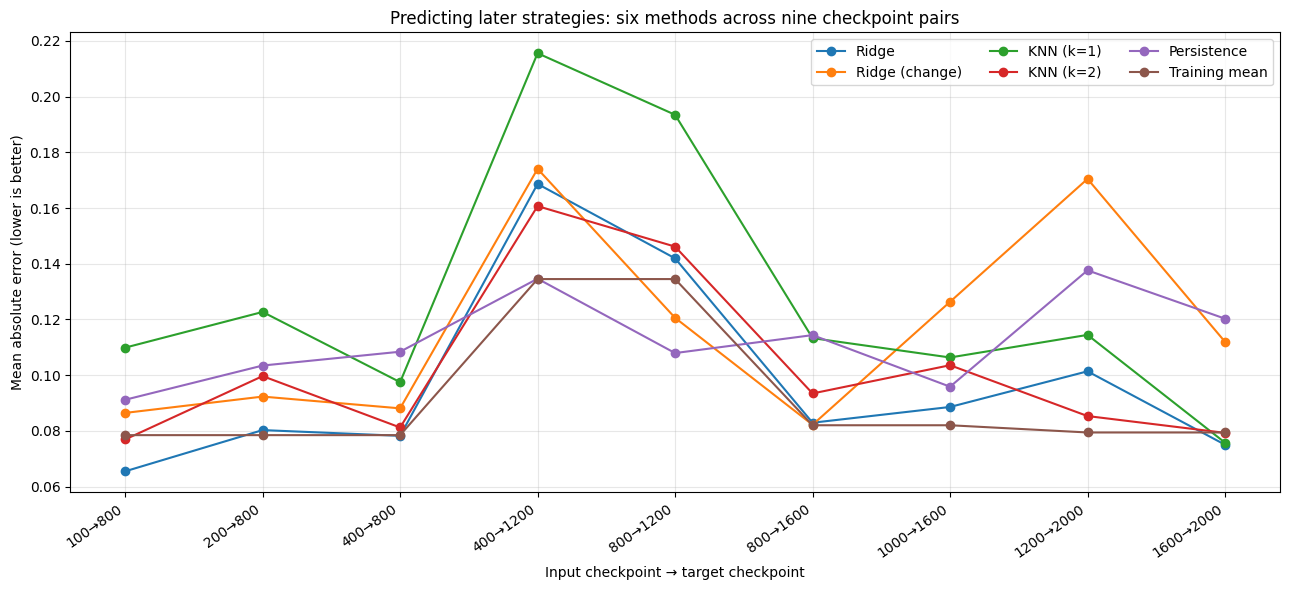

In [33]:
# CELL 33 — Prediction comparison plot

labels = [f"{source}→{target}" for source, target, _ in method_summary.index]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(13, 6))
for method in method_names:
    ax.plot(x, method_summary[method].to_numpy(), marker="o", label=method)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set(xlabel="Input checkpoint → target checkpoint",
       ylabel="Mean absolute error (lower is better)",
       title="Predicting later strategies: six methods across nine checkpoint pairs")
ax.grid(alpha=0.3)
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

I tested whether an agent's earlier strategy fingerprint could predict its behavior at a later checkpoint. I compared Ridge regression, two KNN models, Ridge predicting changes, and two simple baselines. I used leave-one-agent-out validation (so took out 1 from 5) so the model was tested on an agent it had not trained on. The training-mean baseline performed best overall, with an average error of about 0.0919 and the lowest error in five of the nine checkpoint comparisons. Ridge was close, but no learned method consistently performed better than the simple baseline. With only five agents, the results suggest that predicting future strategies is difficult and would need more models and data to improve.


While Ridge performed worse overall than the training-mean baseline, it still gave reasonably close predictions in some cases. This is important for my overall project because it shows that early behavior can provide some useful information about how an agent might behave later. Although my meta-model was not consistently better than the simple baseline, the results suggest that predicting future strategies from earlier behavior is possible and did happen, but more agents and training data would be needed to make these predictions more reliable.

## Limitations and Future Work

One of the biggest limitations of this project was that I only trained five agents. This was enough to compare their behavior and see differences between them, but it gave the meta-model very little data to learn from. I also reused the same five agents across nine checkpoint comparisons, meaning these were not nine completely independent experiments. Training more agents would give me a larger variety of strategies and help me understand whether my results apply beyond these five agents.

Another limitation was the training itself. Although I extended training from 800 to 2,000 episodes, this does not mean the agents had fully learned how to play 2048. Their reward scores were still relatively low, and their strategies continued changing. Also, when training resumed from episode 800, the network weights were restored, but the optimizer and replay memory were restarted. This may have affected how the agents learned during the continuation. More training and better tuning of the DQN settings could help me get stronger and more stable agents. DQN in itself, may have been another issue due to the epsilon-greedy action selection introducing a random component where the model would choose between a random move and its best move (decided by its current policy) so that caused points in training where a model performed better initially and then somehow became worse later.

I also had limitations in how I measured behavior. My strategy fingerprints used features such as merge rate, corner preference, empty spaces, and action frequencies. These gave me a way to compare agents, but they cannot capture every part of an agent's strategy. 

For my main project question, I found that agents trained with the same settings could develop different behaviors, and these differences continued changing over time. For the prediction question, Ridge regression sometimes predicted later behavior reasonably well, but it did not consistently beat the simple training-mean baseline. This does not mean the prediction idea failed completely. It shows that there may be useful information in early behavior, but my current project's scope was too limited to demonstrate reliable prediction.

If I continued this project, the main improvements would be training more agents, improving their 2048 performance, and collecting more detailed strategy features. 

Overall, this project showed that agents learning the same game do not necessarily develop identical strategies. Even though my prediction results were limited, they gave me a useful starting point for understanding how reinforcement learning agents develop their behavior over time.